# M08-4 | 真的變快了嗎：eager、Q/DQ 圖、fp32 `.pte`、int8 `.pte`

M07 沒有 int8 kernel，所以不量速度；XNNPACK 有。同一個模型，比四種執行方式：

| 執行方式 | 怎麼來的 | 跑的是 |
|---|---|---|
| eager fp32 | 原模型 | PyTorch eager，每個 op 經過 Python 與 dispatcher |
| Q/DQ 圖 | `convert_pt2e` 的結果 | PyTorch eager：fp32 運算，再加上 q/dq |
| fp32 `.pte` | 原模型不量化，直接 lower | ExecuTorch + XNNPACK 的 fp32 kernel |
| int8 `.pte` | Q/DQ 圖再 lower（M08-2） | ExecuTorch + XNNPACK 的 int8 kernel |

先預測：Q/DQ 圖會比 eager 快嗎？int8 `.pte` 的加速該和誰比？

- **A.** 兩種寬度的 TinyConvNet，batch 1 的 latency。
- **B.** 把收益拆成兩段：換 runtime、再量化。

**數字和機器強相關**（CPU、執行緒數、XNNPACK 版本），只看相對關係；下面存的輸出來自開頭印出的環境，說明依實測產生。這本 notebook 需要 executorch（`uv sync --group executorch`）。

In [1]:
import timeit

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.pt2e import quiet  # 必須在 executorch 之前 import
from common.env import env_summary
from common.executorch_utils import PteRunner, lower_to_xnnpack, xnnpack_ptq
from common.models import TinyConvNet, example_inputs
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
print(env_summary())

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True


## A. batch 1 的 latency

`width` 是 TinyConvNet 中間層 conv 的 channel 數（`head_conv` 是 2×width）。兩種寬度的輸入大小與 batch 相同，差別只在每層的計算量。

計時方式：每種先暖身 20 次，再做 7 輪、每輪 100 次，取最快一輪的平均（最不受背景程序干擾）。latency 和 weight 的值無關，所以用沒訓練過的模型、少量校準就好。

In [2]:
@torch.no_grad()
def latency_us(fn, x, warmup=20, number=100, repeat=7):
    for _ in range(warmup):
        fn(x)
    return min(timeit.repeat(lambda: fn(x), number=number, repeat=repeat)) / number * 1e6


def measure(width):
    """回傳 (參數量, {執行方式: 微秒})。"""
    torch.manual_seed(0)
    model = TinyConvNet(width=width).eval()
    x = example_inputs(1)
    qdq = xnnpack_ptq(model, x, n_calib=32)
    runners = {
        "eager fp32": model,
        "Q/DQ 圖": qdq,
        "fp32 .pte": PteRunner(lower_to_xnnpack(model, x)[1]),
        "int8 .pte": PteRunner(lower_to_xnnpack(qdq, x)[1]),
    }
    n_params = sum(p.numel() for p in model.parameters())
    return n_params, {name: latency_us(fn, x[0]) for name, fn in runners.items()}


WIDTHS = [16, 64]
results = {w: measure(w) for w in WIDTHS}
METHODS = list(results[WIDTHS[0]][1])
table([[f"width={w}（{n} 個參數）"] + [f"{t[m]:.1f}" for m in METHODS] for w, (n, t) in results.items()],
      ["微秒（越小越快）"] + METHODS)

微秒（越小越快）,eager fp32,Q/DQ 圖,fp32 .pte,int8 .pte
width=16（9940 個參數）,240.7,497.2,36.6,26.9
width=64（150340 個參數）,308.0,862.9,98.8,54.6


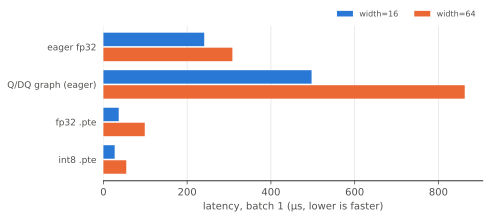

In [3]:
#| code-fold: true
#| code-summary: 畫圖的程式
LABELS = {"eager fp32": "eager fp32", "Q/DQ 圖": "Q/DQ graph (eager)", "fp32 .pte": "fp32 .pte", "int8 .pte": "int8 .pte"}
COLORS = {16: "#2a78d6", 64: "#eb6834"}
MUTED, GRID = "#52514e", "#e6e5e1"
fig, ax = plt.subplots(figsize=(6.8, 2.8))
h = 0.36
for j, w in enumerate(WIDTHS):
    t = results[w][1]
    ys = [i + (j - 0.5) * (h + 0.04) for i in range(len(METHODS))]
    ax.barh(ys, [t[m] for m in METHODS], height=h, color=COLORS[w], label=f"width={w}")
ax.set_yticks(range(len(METHODS)), [LABELS[m] for m in METHODS], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("latency, batch 1 (µs, lower is faster)", color=MUTED)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=MUTED, left=False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=2, frameon=False, labelcolor=MUTED, fontsize=8)
plt.show()

## B. 收益分兩段：換 runtime、再量化

```text
eager fp32 ──換 runtime──→ fp32 .pte ──量化──→ int8 .pte
```

把每一段的倍數算出來，Q/DQ 圖對 eager 當對照：

In [4]:
def speedup(before_us, after_us):
    """從 before 換成 after：after 較快印「N× 快」，較慢印「N× 慢」。"""
    ratio = before_us / after_us
    return f"{ratio:.2f}× 快" if ratio >= 1 else f"{1 / ratio:.2f}× 慢"


table([[f"width={w}", speedup(t["eager fp32"], t["fp32 .pte"]), speedup(t["fp32 .pte"], t["int8 .pte"]),
        speedup(t["eager fp32"], t["Q/DQ 圖"])] for w, (_, t) in results.items()],
      ["", "換 runtime（eager → fp32 .pte）", "量化（fp32 .pte → int8 .pte）", "對照（eager → Q/DQ 圖）"])

,換 runtime（eager → fp32 .pte）,量化（fp32 .pte → int8 .pte）,對照（eager → Q/DQ 圖）
width=16,6.58× 快,1.36× 快,2.07× 慢
width=64,3.12× 快,1.81× 快,2.80× 慢


In [5]:
small, large = (results[w][1] for w in WIDTHS)
n_small, n_large = (results[w][0] for w in WIDTHS)
if all(t["Q/DQ 圖"] > t["eager fp32"] for _, t in results.values()):
    print("* Q/DQ 圖比 eager 慢：它仍是 fp32 運算，只是多了 q/dq。")
if all(t["fp32 .pte"] < t["eager fp32"] for _, t in results.values()):
    print("* 不量化的 fp32 .pte 就比 eager 快很多：整張圖一次交給 XNNPACK，省掉每個 op 經過 Python 與 dispatcher 的開銷。")
    print(f"  參數量變 {n_large / n_small:.0f} 倍，eager 只慢了 {large['eager fp32'] / small['eager fp32']:.1f} 倍："
          "eager 的時間大多花在呼叫開銷，不是計算（推論）。")
gain_small, gain_large = (t["fp32 .pte"] / t["int8 .pte"] for t in (small, large))
if gain_small > 1 and gain_large > gain_small:
    print(f"* int8 對 fp32 .pte 的加速：width 16 是 {gain_small:.2f} 倍、width 64 是 {gain_large:.2f} 倍，計算量越大越明顯。")
    print("  模型太小時，固定開銷（呼叫、輸入輸出的 fp32 ↔ int8 轉換）占比高（推論，只量了兩個寬度）。")
elif gain_small > 1 or gain_large > 1:
    print(f"* int8 .pte 對 fp32 .pte 的加速：{gain_small:.2f}／{gain_large:.2f} 倍，沒有隨寬度變大。")
else:
    print("* 在這台機器上，int8 .pte 沒有比 fp32 .pte 快：XNNPACK 的 int8 kernel 快不快，取決於 CPU 的指令集。")

* Q/DQ 圖比 eager 慢：它仍是 fp32 運算，只是多了 q/dq。
* 不量化的 fp32 .pte 就比 eager 快很多：整張圖一次交給 XNNPACK，省掉每個 op 經過 Python 與 dispatcher 的開銷。
  參數量變 15 倍，eager 只慢了 1.3 倍：eager 的時間大多花在呼叫開銷，不是計算（推論）。
* int8 對 fp32 .pte 的加速：width 16 是 1.36 倍、width 64 是 1.81 倍，計算量越大越明顯。
  模型太小時，固定開銷（呼叫、輸入輸出的 fp32 ↔ int8 轉換）占比高（推論，只量了兩個寬度）。


「部署後變快」要分兩段看：換 runtime 的收益與量化的收益是兩件事。所以比較 int8 時，基準是**同一個 runtime 的 fp32**（fp32 `.pte`），不是 PyTorch eager（M07 概覽〈速度的基準〉）。

## 小結

- 量化本身不會變快，Q/DQ 圖在 eager 裡反而更慢；要有後端把它換成 int8 kernel。
- 換到 ExecuTorch + XNNPACK，fp32 就已經快很多；int8 的收益要拿 fp32 `.pte` 當基準。
- 這裡的模型很小，量到的有一部分是呼叫開銷；實際收益要用自己的模型、在目標裝置上量。